In [24]:
# %pip install torch torchvision pytorchvideo opencv-python pandas numpy matplotlib scikit-learn

In [25]:
from pathlib import Path
import os
import sys
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

# check the root for the path
MATERIALS_DIR = Path("/projectnb/cs541/materials")

ROOT = next(
    (
        p for p in MATERIALS_DIR.iterdir()
        if p.is_dir()
        and (p / "starter" / "cpr_data.py").is_file()
        and (p / "train.csv").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError

WORK_DIR = Path("/projectnb/cs541/students/liting99")

sys.path.insert(0, str(ROOT / "starter"))
os.environ["CPR_DATA"] = str(ROOT)

import cpr_data
cpr_data.LOCAL_ROOT = str(ROOT)

OUTPUT_DIR = WORK_DIR / "outputs" / "x3d_m"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", ROOT)
print("Personal directory:", WORK_DIR)
print("Outputs:", OUTPUT_DIR)
print("Device:", DEVICE)

Dataset: /projectnb/cs541/materials/cpr_challenge
Personal directory: /projectnb/cs541/students/liting99
Outputs: /projectnb/cs541/students/liting99/outputs/x3d_m
Device: cuda


In [26]:
train = pd.read_csv(cpr_data.data_file('train.csv'))
sample = pd.read_csv(cpr_data.data_file('sample_submission.csv'))
labels = list(sample.columns[1:])
NUM_CLASSES = len(labels)
assert NUM_CLASSES == 13
assert set(labels).issubset(train.columns)

print('Training videos:', len(train))
print('Test videos:', len(sample))
print('Error labels:', labels)
display(train[['video_id', 'class_name', *labels]].head(3))

Training videos: 1008
Test videos: 4320
Error labels: ['e01_overlap_hands', 'e02_clenching_hands', 'e03_single_hand', 'e04_bending_arms', 'e05_tilting_arms', 'e06_jump_pressing', 'e07_squatting', 'e08_standing', 'e09_wrong_position', 'e10_insufficient_pressing', 'e11_slow_frequency', 'e12_excessive_pressing', 'e13_random_position_pressing']


,video_id,class_name,e01_overlap_hands,e02_clenching_hands,e03_single_hand,e04_bending_arms,e05_tilting_arms,e06_jump_pressing,e07_squatting,e08_standing,e09_wrong_position,e10_insufficient_pressing,e11_slow_frequency,e12_excessive_pressing,e13_random_position_pressing
0,CPR_Dataset_S0__C00_S0__r00__ch0,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0
1,CPR_Dataset_S0__C00_S0__r00__ch1,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0
2,CPR_Dataset_S0__C00_S0__r00__ch2,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0


Train & Validation Split of 'take' recordings. MAke sure validation measures performance on different CPR attempts, not just different views of attempts the model has already seen.

In [27]:
take_table = train.groupby('take', as_index=False).agg(class_id=('class_id', 'first'))
class_take_counts = take_table['class_id'].value_counts()
print('Independent takes per class:')
display(class_take_counts.sort_index().rename('takes').to_frame())


train_takes, val_takes = train_test_split(
    take_table['take'], test_size=0.20, random_state=SEED,
    stratify=take_table['class_id']
)
train_split = train[train['take'].isin(train_takes)].reset_index(drop=True)
val_split = train[train['take'].isin(val_takes)].reset_index(drop=True)
print('Training videos:', len(train_split), 
      '\nValidation videos:', len(val_split))
display(pd.DataFrame({
    'train': train_split['class_name'].value_counts(),
    'validation': val_split['class_name'].value_counts()
}).fillna(0).astype(int))
print('View distribution:')
display(pd.DataFrame({
    'train': train_split['view'].value_counts(),
    'validation': val_split['view'].value_counts()
}).fillna(0).astype(int))

Independent takes per class:


,takes
class_id,
0,24
1,24
2,24
3,24
4,24
5,24
6,24
7,24
8,24


Training videos: 804 
Validation videos: 204


,train,validation
class_name,,
Bending Arms,57,15
Clenching Hands,57,15
Correct,57,15
Excessive Pressing,57,15
Insufficient Pressing,57,15
Jump Pressing,57,15
Overlap Hands,57,15
Random Position Pressing,57,15
Single Hand,57,15


View distribution:


,train,validation
view,,
ch0,268,68
ch1,268,68
ch2,268,68


### Read an video as a PyTorch tensor

Video: CPR_Dataset_S0__C00_S0__r00__ch0  class: Correct
[T,H,W,C]: (16, 256, 256, 3) torch.uint8
Sampled frame times (seconds): [0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2.  2.2 2.4 2.6 2.8 3. ]


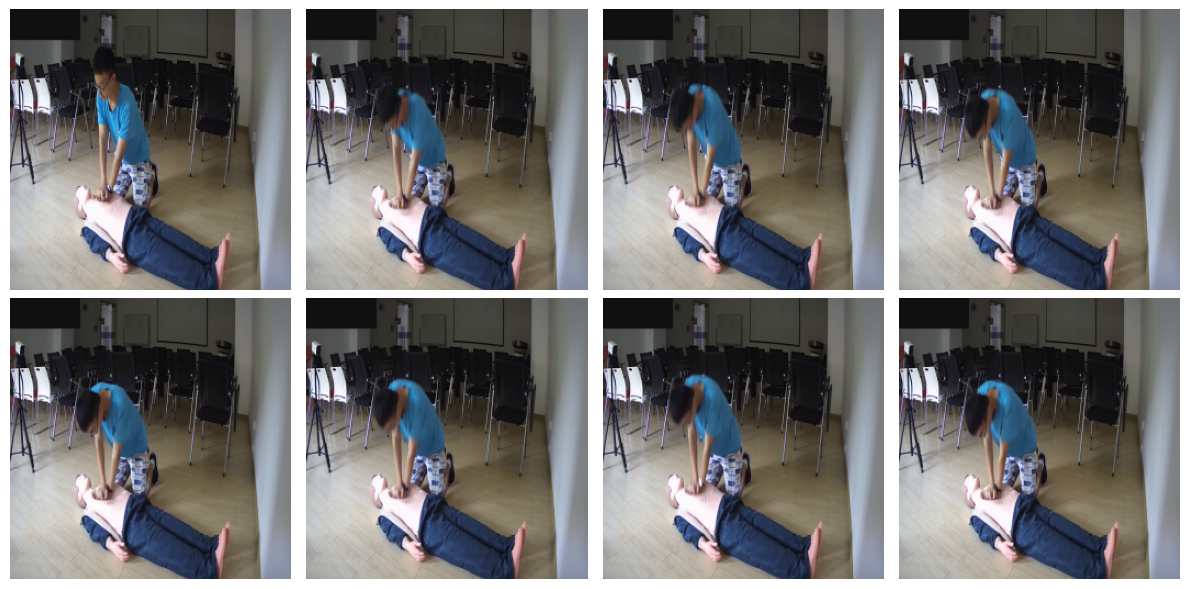

In [28]:
NUM_FRAMES = 16
FRAME_STRIDE = 5
SIZE = 256
FPS = 25  # frames per second

row = train.iloc[0]
video_path = cpr_data.video_file(row.video_id, 'train')
frames = cpr_data.load_video(
    video_path, stride=FRAME_STRIDE, max_frames=NUM_FRAMES, size=(SIZE, SIZE)
)
raw_video = torch.from_numpy(np.ascontiguousarray(frames))

print('Video:', row.video_id, ' class:', row.class_name)
print('[T,H,W,C]:', tuple(raw_video.shape), raw_video.dtype)
print('Sampled frame times (seconds):', (np.arange(len(frames)) * FRAME_STRIDE / FPS).round(2))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.axis('off')
for ax, idx in zip(axes.flat, np.linspace(0, len(frames)-1, min(8, len(frames)), dtype=int)):
    ax.imshow(frames[idx])
plt.tight_layout()
plt.show()

### Convert input to match X3D-m
X3D-M's expected input [B,C,T,H,W], so need to reorder our [T,H,W,C] to be [C,T,H,W], and also apply normalization with the X3D recipe's RGB mean 0.45 and standard deviation 0.225

In [29]:
def preprocess_video(frames, num_frames=NUM_FRAMES):
    if len(frames) == 0:
        raise ValueError('No frames')
    frames = frames[:num_frames]
    if len(frames) < num_frames:
        frames = np.concatenate(
            [frames, np.repeat(frames[-1:], num_frames - len(frames), axis=0)],
            axis=0
        )

    video = torch.from_numpy(np.ascontiguousarray(frames)).float() / 255.0
    video = video.permute(3, 0, 1, 2)      # [C,T,H,W]
    video = (video - 0.45) / 0.225        # X3D mean/std
    return video

x = preprocess_video(frames).unsqueeze(0).to(DEVICE)
print('Input shade:', tuple(x.shape))

Input shade: (1, 3, 16, 256, 256)


### Load pretrained X3D-M
Replace its original network ends in 400 classification to 13 for our case 

In [30]:
model = torch.hub.load(
    'facebookresearch/pytorchvideo', 'x3d_m', pretrained=True
)

head = model.blocks[-1]

d = head.proj.in_features
head.proj = nn.Linear(d, NUM_CLASSES)       # REPLACE to be our own class size
head.activation = nn.Identity()            # keep raw logits

model = model.to(DEVICE)
print('New classifier:', model.blocks[-1].proj)

New classifier: Linear(in_features=2048, out_features=13, bias=True)


Using cache found in /usr4/ds340/liting99/.cache/torch/hub/facebookresearch_pytorchvideo_main


Forward pass after replacement

In [31]:
model.eval()
with torch.no_grad():
    logits = model(x)                       # forward only

print("Output shape:", logits.shape)

Output shape: torch.Size([1, 13])


### Freeze N-3 layers, finetune the last three layers(last two backbone blocks + last FC)
freeze the pretrained backbone and train just the three layers, then measure held-out macro-F1.

In [32]:
class CPRDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, idx):
        row = self.table.iloc[idx]
        frames = cpr_data.load_video(
            cpr_data.video_file(row.video_id, 'train'),
            stride=FRAME_STRIDE,
            max_frames=NUM_FRAMES,
            size=(SIZE, SIZE),
        )
        video = preprocess_video(frames)  
        target = torch.tensor(row[labels].to_numpy(dtype=np.float32))
        return video, target              # [3,T,H,W], [13]

BATCH_SIZE = 2  
train_loader = DataLoader(
    CPRDataset(train_split), batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=(DEVICE.type == 'cuda'),
)
val_loader = DataLoader(
    CPRDataset(val_split), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=(DEVICE.type == 'cuda'),
)

batch_video, batch_targets = next(iter(train_loader))
print('Video batch:', tuple(batch_video.shape))
print('Target batch:', tuple(batch_targets.shape))

Video batch: (2, 3, 16, 256, 256)
Target batch: (2, 13)


Freeze all pretrained weights, train only new FC

In [33]:
# freeze all level first anad then unfreeze only the new fc layer
for parameter in model.parameters():
    parameter.requires_grad = False

for block in (model.blocks[-3], model.blocks[-2]):
    for parameter in block.parameters():
        parameter.requires_grad = True

for parameter in model.blocks[-1].proj.parameters():
    parameter.requires_grad = True

frozen_prefix = nn.Sequential(*list(model.blocks)[:-3]).to(DEVICE)
trainable_suffix = nn.Sequential(*list(model.blocks)[-3:]).to(DEVICE)

# trainable = [
#     (name, tuple(p.shape)) 
#     for name, p in model.named_parameters() 
#     if p.requires_grad]
# print('Trainable tensors:', trainable)

for index, block in enumerate(model.blocks):
    count = sum(p.numel() for p in block.parameters() if p.requires_grad)
    print(f'Block {index}: trainable parameters = {count:,}')

criterion = nn.BCEWithLogitsLoss() # loss function with binary cross entropy
optimizer = torch.optim.AdamW(model.blocks[-1].proj.parameters(), lr=1e-3, weight_decay=1e-4)
THRESHOLD = 0.5
CHECKPOINT = OUTPUT_DIR / 'x3d_m_fc_only_best.pt'


Block 0: trainable parameters = 0
Block 1: trainable parameters = 0
Block 2: trainable parameters = 0
Block 3: trainable parameters = 569,256
Block 4: trainable parameters = 1,347,440
Block 5: trainable parameters = 26,637


In [34]:
import hashlib
import json
from torch.utils.data import TensorDataset

# saving the output of the frozen layers to increase the speed in every training epoch
def feature_cache_path(table, split_name):
    settings = {
        'version': 'x3d_m_frozen_prefix',
        'split': split_name,
        'video_ids': table['video_id'].astype(str).tolist(),
        'targets': table[labels].astype(int).values.tolist(),
        'labels': labels,
        'num_frames': NUM_FRAMES,
        'frame_stride': FRAME_STRIDE,
        'size': SIZE,
        'backbone': 'facebookresearch/pytorchvideo:x3d_m:pretrained',
        'cache_boundary': f'before_block_{len(model.blocks)-3}',
    }
    signature = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
    return OUTPUT_DIR / f'{split_name}_prefix_{signature}.pt'

@torch.no_grad()
def get_or_create_features(table, split_name):
    cache_path = feature_cache_path(table, split_name)
    if cache_path.exists():
        cached = torch.load(cache_path, map_location='cpu', weights_only=True)
        print(f'{split_name}: loaded {len(cached["features"])} cached prefix activations from {cache_path.name}')
        return TensorDataset(cached['features'], cached['targets'])

    frozen_prefix.eval()
    features, targets_all = [], []
    loader = DataLoader(
        CPRDataset(table), batch_size=BATCH_SIZE, shuffle=False,
        num_workers=0, pin_memory=(DEVICE.type == 'cuda'),
    )
    started = time.time()
    for batch_idx, (videos, targets) in enumerate(loader, start=1):
        activations = frozen_prefix(videos.to(DEVICE, non_blocking=True))
        # Keep cached tensors in float32 for consistent downstream computation.
        features.append(activations.cpu())
        targets_all.append(targets.cpu())
        if batch_idx % 25 == 0 or batch_idx == len(loader):
            print(f'{split_name}: cached {min(batch_idx * BATCH_SIZE, len(table))}/{len(table)} '
                  f'videos ({time.time()-started:.1f}s)')

    dataset = TensorDataset(torch.cat(features), torch.cat(targets_all))
    torch.save({'features': dataset.tensors[0], 'targets': dataset.tensors[1]}, cache_path)
    memory_gb = dataset.tensors[0].numel() * dataset.tensors[0].element_size() / 1e9
    print(f'{split_name}: saved {cache_path.name}, shape {tuple(dataset.tensors[0].shape)} '
          f'({memory_gb:.2f} GB)')
    return dataset

# Once per train/validation video (unless the appropriate cache already exists).
train_features = get_or_create_features(train_split, 'train')
val_features = get_or_create_features(val_split, 'val')

# Intermediate feature maps are much larger than FC vectors; keep modest batches.
FEATURE_BATCH_SIZE = 2
train_feature_loader = DataLoader(
    train_features, batch_size=FEATURE_BATCH_SIZE, shuffle=True,
    pin_memory=(DEVICE.type == 'cuda'),
)
val_feature_loader = DataLoader(
    val_features, batch_size=FEATURE_BATCH_SIZE, shuffle=False,
    pin_memory=(DEVICE.type == 'cuda'),
)

train: loaded 804 cached prefix activations from train_prefix_f178c128f32b8c51.pt
val: loaded 204 cached prefix activations from val_prefix_511db66f3fa58158.pt


### Evaluate with macro-F1

Apply sigmoid to obtain 13 scores in [0,1], then threshold each score to produce binary predictions.

In [41]:
@torch.no_grad()
def evaluate(model, loader, threshold=THRESHOLD):
    model.eval()

    total_loss = 0.0
    all_probs = []
    all_targets = []

    for features, targets in loader:
        features = features.to(DEVICE)
        targets = targets.to(DEVICE)

        # Cached features start at Block 3
        logits = trainable_suffix(features)
        loss = criterion(logits, targets)

        total_loss += loss.item() * len(features)
        all_probs.append(torch.sigmoid(logits).cpu())
        all_targets.append(targets.cpu())

    probs = torch.cat(all_probs).numpy()
    targets = torch.cat(all_targets).numpy()
    predictions = (probs >= threshold).astype(int)

    return {
        "loss": total_loss / len(loader.dataset),
        "macro_f1": f1_score(
            targets, predictions, average="macro", zero_division=0
        ),
        "precision_macro": precision_score(
            targets, predictions, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            targets, predictions, average="macro", zero_division=0
        ),
        "probs": probs,
        "targets": targets,
        "predictions": predictions,
    }

def per_error_report(metrics):
    y_true = metrics['targets']
    y_pred = metrics['predictions']

    return pd.DataFrame({
        'error': labels,
        'validation_positives': y_true.sum(axis=0),
        'predicted_positives': y_pred.sum(axis=0),
        'precision': precision_score(
            y_true, y_pred, average=None, zero_division=0
        ),
        'recall': recall_score(
            y_true, y_pred, average=None, zero_division=0
        ),
        'f1': f1_score(
            y_true, y_pred, average=None, zero_division=0
        ),
    })

Train the FC layer for a few epochs

In [36]:
EPOCHS = 20
PATIENCE = 5
epochs_without_improvement = 0


history = []
best_f1 = -1.0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    model.eval()  # keep frozen prefix and head BatchNorm/dropout behavior fixed
    model.blocks[-3].train()
    model.blocks[-2].train()
    model.blocks[-1].proj.train()
    running_loss = 0.0

    # receives feature rather than original video frames
    for features, targets in train_feature_loader:
        features = features.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = trainable_suffix(features)  # res4 + res5 + X3D head/FC
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(features)

    train_loss = running_loss / len(train_feature_loader.dataset)
    valid = evaluate(model, val_feature_loader)
    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': valid['loss'],
        'val_macro_f1': valid['macro_f1'],
        'val_macro_precision': valid['precision_macro'],
        'val_macro_recall': valid['recall_macro'],
    })

    # if valid['macro_f1'] > best_f1:
    #     best_f1 = valid['macro_f1']
    #     torch.save({
    #         'model_state_dict': model.state_dict(),
    #         'labels': labels,
    #         'epoch': epoch,
    #         'threshold': THRESHOLD,
    #         'val_macro_f1': best_f1,
    #         'strategy': 'last2_backbone_plus_fc_cached_prefix',
    #     }, CHECKPOINT)

    # add early stopping 


    if valid['macro_f1'] > best_f1:
        best_f1 = valid['macro_f1']
        epochs_without_improvement = 0

        torch.save({
            'model_state_dict': model.state_dict(),
            'labels': labels,
            'epoch': epoch,
            'threshold': THRESHOLD,
            'val_macro_f1': best_f1,
            'strategy': 'last2_backbone_plus_fc_cached_prefix',
        }, CHECKPOINT)

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

    print(f"Epoch {epoch}: "
        f"train BCE={train_loss:.4f} ; val BCE={valid['loss']:.4f} ；"
        f"val macro-F1={valid['macro_f1']:.4f} ")

history_df = pd.DataFrame(history)
display(history_df)

Epoch 1: train BCE=0.2100 ; val BCE=0.1476 ；val macro-F1=0.3596 
Epoch 2: train BCE=0.1375 ; val BCE=0.1173 ；val macro-F1=0.5032 
Epoch 3: train BCE=0.1115 ; val BCE=0.1104 ；val macro-F1=0.5971 
Epoch 4: train BCE=0.0951 ; val BCE=0.0867 ；val macro-F1=0.7180 
Epoch 5: train BCE=0.0832 ; val BCE=0.0926 ；val macro-F1=0.6527 
Epoch 6: train BCE=0.0754 ; val BCE=0.0824 ；val macro-F1=0.7070 
Epoch 7: train BCE=0.0701 ; val BCE=0.0717 ；val macro-F1=0.7851 
Epoch 8: train BCE=0.0647 ; val BCE=0.0749 ；val macro-F1=0.7710 
Epoch 9: train BCE=0.0600 ; val BCE=0.0660 ；val macro-F1=0.8415 
Epoch 10: train BCE=0.0541 ; val BCE=0.0631 ；val macro-F1=0.8135 
Epoch 11: train BCE=0.0525 ; val BCE=0.0662 ；val macro-F1=0.8154 
Epoch 12: train BCE=0.0479 ; val BCE=0.0673 ；val macro-F1=0.7893 
Epoch 13: train BCE=0.0497 ; val BCE=0.0641 ；val macro-F1=0.8192 
Early stopping at epoch 14


,epoch,train_loss,val_loss,val_macro_f1,val_macro_precision,val_macro_recall
0,1,0.210038,0.147632,0.359647,0.681319,0.307692
1,2,0.137475,0.117320,0.503182,0.816748,0.443590
2,3,0.111531,0.110364,0.597094,0.927137,0.537179
3,4,0.095056,0.086723,0.718033,0.839275,0.648718
4,5,0.083191,0.092647,0.652723,0.800402,0.608974
5,6,0.075407,0.082443,0.706977,0.889348,0.644872
6,7,0.070075,0.071749,0.785120,0.895448,0.729487
7,8,0.064735,0.074936,0.771038,0.927524,0.717949
8,9,0.059968,0.066036,0.841463,0.913324,0.800000
9,10,0.054086,0.063109,0.813513,0.902667,0.762821


Reload the best epoch, calculate validation metrics again, and got the F1 scores

Best epoch: 9
Validation macro-F1: 0.8415
Validation macro-precision: 0.9133
Validation macro-recall: 0.8000


,error,validation_positives,predicted_positives,precision,recall,f1
0,e01_overlap_hands,15.0,8,1.000000,0.533333,0.695652
1,e02_clenching_hands,15.0,12,0.916667,0.733333,0.814815
2,e03_single_hand,15.0,16,0.937500,1.000000,0.967742
3,e04_bending_arms,15.0,13,1.000000,0.866667,0.928571
4,e05_tilting_arms,15.0,14,0.928571,0.866667,0.896552
5,e06_jump_pressing,15.0,10,1.000000,0.666667,0.800000
6,e07_squatting,15.0,11,1.000000,0.733333,0.846154
7,e08_standing,15.0,15,1.000000,1.000000,1.000000
8,e09_wrong_position,12.0,14,0.857143,1.000000,0.923077
9,e10_insufficient_pressing,15.0,20,0.600000,0.800000,0.685714


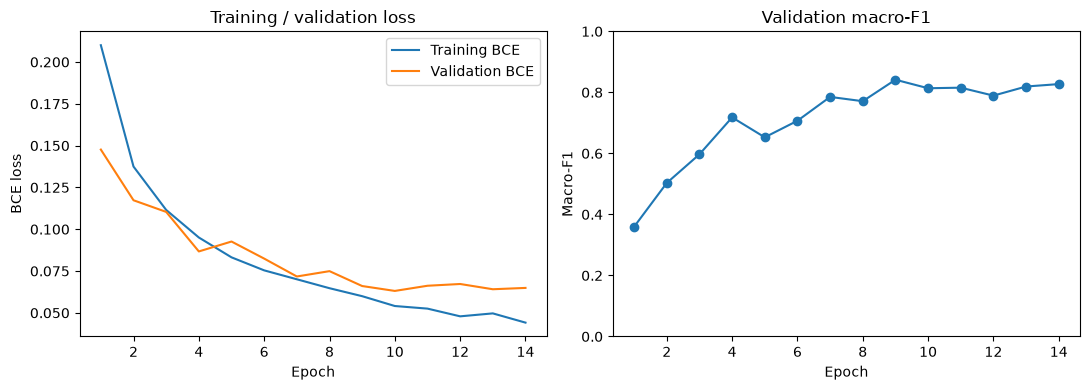

In [42]:
checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint['model_state_dict'])

# Evaluate using cached validation features
best_metrics = evaluate(
    model,
    val_feature_loader,
    threshold=checkpoint['threshold']
)

print('Best epoch:', checkpoint['epoch'])
print(f"Validation macro-F1: {best_metrics['macro_f1']:.4f}")
print(f"Validation macro-precision: {best_metrics['precision_macro']:.4f}")
print(f"Validation macro-recall: {best_metrics['recall_macro']:.4f}")

display(per_error_report(best_metrics))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    history_df['epoch'],
    history_df['train_loss'],
    label='Training BCE'
)
axes[0].plot(
    history_df['epoch'],
    history_df['val_loss'],
    label='Validation BCE'
)
axes[0].set(
    xlabel='Epoch',
    ylabel='BCE loss',
    title='Training / validation loss'
)
axes[0].legend()

axes[1].plot(
    history_df['epoch'],
    history_df['val_macro_f1'],
    marker='o'
)
axes[1].set(
    xlabel='Epoch',
    ylabel='Macro-F1',
    title='Validation macro-F1',
    ylim=(0, 1)
)

plt.tight_layout()
plt.show()

Load the test dataset

In [43]:
threshold = checkpoint['threshold']

model.eval()

all_predictions = []

with torch.no_grad():
    for video_id in sample['video_id']:

        # Load test video
        frames = cpr_data.load_video(
            cpr_data.video_file(video_id, 'test'),
            stride=FRAME_STRIDE,
            max_frames=NUM_FRAMES,
            size=(SIZE, SIZE)
        )

        # Preprocess: [T,H,W,C] -> [3,T,H,W]
        video = preprocess_video(frames)

        # Add batch dimension: [3,T,H,W] -> [1,3,T,H,W]
        video = video.unsqueeze(0).to(DEVICE)

        # Forward pass
        logits = model(video)

        # Convert logits to probabilities
        probabilities = torch.sigmoid(logits)

        # Convert probabilities to binary predictions
        predictions = (probabilities >= threshold).int()

        all_predictions.append(predictions[0].cpu().numpy())

all_predictions = np.array(all_predictions)

print('Test predictions:', all_predictions.shape)

Test predictions: (4320, 13)


### Export Submission


In [44]:
submission = sample.copy()
submission[labels] = all_predictions
cpr_data.check_submission(submission, sample)

# Save CSV
submission_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)

print('Submission saved:', submission_path)
display(submission.head())

Submission saved: /projectnb/cs541/students/liting99/outputs/x3d_m/submission.csv


,video_id,e01_overlap_hands,e02_clenching_hands,e03_single_hand,e04_bending_arms,e05_tilting_arms,e06_jump_pressing,e07_squatting,e08_standing,e09_wrong_position,e10_insufficient_pressing,e11_slow_frequency,e12_excessive_pressing,e13_random_position_pressing
0,000f31ac,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0012a6ff,0,0,1,0,0,0,0,0,0,0,0,0,0
2,002930be,0,0,1,0,0,0,0,0,0,0,0,0,0
3,00293fa6,0,0,0,0,0,0,0,0,0,0,0,0,0
4,002d37f9,0,0,0,0,0,0,0,0,0,0,1,0,0


In [45]:
# Number of predicted errors per test video
error_counts = submission[labels].sum(axis=1)

print('Predicted errors per video:')
print(error_counts.value_counts().sort_index())

print('Total test videos:', len(submission))
print('Videos predicted correct:', (error_counts == 0).sum())
print('Videos with multiple predicted errors:', (error_counts >= 2).sum())

Predicted errors per video:
0    2212
1    1965
2     141
3       2
Name: count, dtype: int64
Total test videos: 4320
Videos predicted correct: 2212
Videos with multiple predicted errors: 143
